# Orientation and direction tuning in `roselab_responsiveness`

This notebook explains, step by step, what `DirectionTuning` stores for every cell of every moving-grating recording,
how each number is computed, how to choose cells and how far each measure can be trusted. Every number is read from
the production schema; one cell is recomputed from its raw trials to show that the table holds exactly what the
formulas say.

**Contents**
1. The angle convention on the screen
2. The standard cell set
3. One cell, step by step: from single trials to every column
4. The population: selectivity, tuning tests, preferred orientations
5. Three trace types, one cell: CASCADE vs OASIS vs dF/F0
6. The double-Gaussian fit and its goodness of fit
7. Direction selectivity
8. Caveats: recordings and ROIs to treat with care
9. Query recipes

Formulas and sources are also in each column comment, in `adamacs/responsiveness/tuning.py` and in the design doc
(`docs/RESPONSIVENESS_SCHEMA_PROPOSAL.md`, sections 2.6 and 2.7).

**Names.** `gosi` / `gdsi` are the global OSI / DSI = 1 − CirVar / 1 − DirCirVar (the recommended measures). Leon's
code and the v1-drift-audit call them `osi` / `dsi`. Here a bare `osi` / `dsi` is always the classic point index
(R_pref − R_orth) / (R_pref + R_orth).

| column | formula | Leon / v1-drift-audit |
|---|---|---|
| `gosi`, `gdsi` | \|F₂\| / F₀, \|F₁\| / F₀ with F_n = Σ_k R_k e^(i n θ_k), F₀ = Σ_k R_k | `osi`, `dsi` |
| `gosi_cv`, `gdsi_cv` | split-half (odd vs even trials) versions; ≤ 0 = no reliable tuning | `osi_cv`, `dsi_cv` |
| `pref_ori`, `pref_dir` | arg(F₂)/2, arg(F₁) | `pref_ori`, `pref_dir` / `po`, `pd` |
| `hotelling_p`, `dir_dot_p` | is the cell orientation / direction tuned? (Mazurek et al. 2014) | — |
| `osi`, `dsi`, `oi`, `di` | point indices from R_pref, R_orth, R_null | — |
| `fit_*` | double Gaussian (Mazurek et al. 2014) and its goodness of fit | — |

**Angles.** The stored label L (`Moving_Gratings:<L>`) is the grating's motion direction, and labels run clockwise
([Slack, 2026-08-20](https://troselab.slack.com/archives/C08ALHT5PMZ/p1787206655842939?thread_ts=1787206224.422849&cid=C08ALHT5PMZ)). Tuning 1 uses θ = (90 − L) mod 360, the convention agreed with the Sinz lab
(export v1.5):

* `pref_ori` is the **bar orientation**: 0° = horizontal bars, 90° = vertical bars.
* `pref_dir` is that convention's direction: the physical motion direction + 90°. Tuning 3 (θ = −L) gives the
  physical motion direction (counter-clockwise from rightward).
* Selectivity values (`gosi`, `osi`, `hotelling_p`, ...) do not depend on the convention, only the angles do.

In [1]:
import os, sys, logging, warnings
warnings.filterwarnings("ignore")
logging.getLogger("datajoint").setLevel(logging.WARNING)      # keeps the server address out of the outputs
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import datajoint as dj
dj.logger.setLevel(logging.WARNING)                                   # after the import: keeps the server address out of the outputs
from IPython.display import display, Markdown

for _c in ("../dj_local_conf.json", "dj_local_conf.json", os.path.expanduser("~/adamacs/dj_local_conf.json")):
    if os.path.exists(_c):
        dj.config.load(_c); break
dj.config["database.use_tls"] = False
dj.config["display.limit"] = 8
dj.conn().query("SET SESSION transaction_read_only = 1")                 # read-only, enforced by the server
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1
vm = lambda db: dj.create_virtual_module(db, db, create_schema=False, create_tables=False)
r, imaging = vm("roselab_responsiveness"), vm("roselab_imaging")

sys.path.insert(0, "..")
from adamacs.responsiveness import tuning as T                           # pure numpy, no database access

mpl.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
COL = {"cascade25": "#e76f51", "oasis": "#2a9d8f", "dff0_r2": "#2b2d42"}
NAME = {"cascade25": "CASCADE", "oasis": "OASIS", "dff0_r2": "dF/F0"}
SEL = {"event_selector": "gratings", "readout_idx": 16, "tuning_idx": 1}
TP = (r.TuningParamSet & SEL).fetch1()
CONV = TP["angle_convention"]
SOMA = imaging.MaskClassification.MaskType & 'mask_type="soma"'
REJ = imaging.RoiQC.Rejected.proj()                                       # every ROI QC criterion (empty_f, second_channel)
CELL = ["session_id", "scan_id", "paramset_idx", "curation_id", "mask", "fluo_channel"]
print("tuning 1:", {k: TP[k] for k in ("angle_convention", "rectify", "fit", "n_perm", "n_boot")})
print("DirectionTuning:", len(r.DirectionTuning & SEL), "read-outs |", len(r.DirectionTuning.Cell & SEL), "cells x trace types")

tuning 1: {'angle_convention': '90_minus_label', 'rectify': 'clip', 'fit': 1, 'n_perm': 1000, 'n_boot': 200}


DirectionTuning: 777 read-outs | 1070842 cells x trace types


## 1. The angle convention on the screen

Each panel is one stimulus label L. Bars and arrow (motion) are drawn in the Bonsai log frame, read as +x right and
+y up on the monitor (the one link that is not recorded anywhere; design doc section 2.7). The title gives θ = 90 − L,
the angle tuning 1 uses; θ mod 180 is the bar orientation.

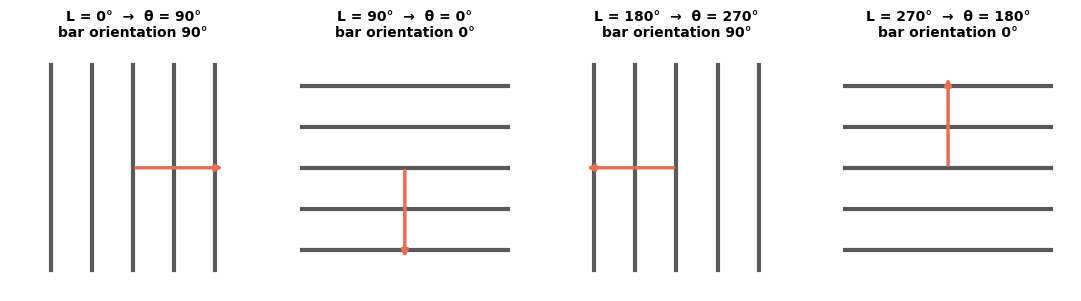

In [2]:
fig, axs = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, L in zip(axs, (0, 90, 180, 270)):
    motion = np.deg2rad(-L)                               # verified: label L moves the pattern along -L in the log frame
    bar = motion + np.pi / 2                              # bars are perpendicular to the motion
    for off in np.linspace(-0.8, 0.8, 5):
        cx, cy = off * np.cos(motion), off * np.sin(motion)
        ax.plot([cx - np.cos(bar), cx + np.cos(bar)], [cy - np.sin(bar), cy + np.sin(bar)], color="0.35", lw=3)
    ax.annotate("", xy=(0.9 * np.cos(motion), 0.9 * np.sin(motion)), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="#e76f51", lw=2.5))
    theta = (90 - L) % 360
    ax.set(title=f"L = {L}°  →  θ = {theta}°\nbar orientation {theta % 180}°", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 2. The standard cell set

The standard grating rule (`gratings_cascade25` and its OASIS twin) uses read-out 16: responsive (paired t-test
p < 0.05), reliable (oracle ≥ 0.18), soma, ROI QC passed. `resp.cells("gratings_cascade25", ...)` applies exactly
that rule (it needs an activated module); here it is written out with plain DataJoint operators so the notebook stays
read-only. Excluding `imaging.RoiQC.Rejected` drops ROIs without fluorescence (`empty_f`) and the second, non-functional
channel of two-channel recordings (`second_channel`).

In [3]:
COLS = ["gosi", "gdsi", "gosi_cv", "gdsi_cv", "gosi_perm_p", "gdsi_perm_p", "pref_ori", "pref_dir", "pref_dir_dot",
        "pref_ori_ci", "hotelling_p", "dir_dot_p", "ori_kw_p", "dir_kw_p", "osi", "dsi", "oi", "di",
        "fit_pref_dir", "fit_sigma", "fit_hwhh", "fit_rp", "fit_rn", "fit_c", "fit_osi", "fit_dsi", "fit_oi", "fit_di",
        "fit_r2", "fit_r2_cv", "fit_chi2_red", "fit_chi2_p", "fit_at_bound"]

def tuning_frame(src, good_only=True):
    key = {**SEL, "trace_source": src}
    q = r.DirectionTuning.Cell & key
    if good_only:
        good = (r.Readout.Cell * SOMA - REJ) & {k: key[k] for k in ("event_selector", "trace_source", "readout_idx")} \
               & "resp_p < 0.05 AND oracle_r >= 0.18"
        q = q & good.proj()
    d = q.proj(*COLS).fetch(format="frame").reset_index()
    for c in COLS:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d["trace_source"] = src
    return d

D = {s: tuning_frame(s) for s in ("cascade25", "oasis", "dff0_r2")}
ALL = {s: tuning_frame(s, good_only=False) for s in ("cascade25", "oasis", "dff0_r2")}
summary = pd.DataFrame({NAME[s]: {"all cells (soma or not)": len(ALL[s]), "responsive + reliable soma": len(D[s]),
                                  "recordings": D[s].scan_id.nunique()} for s in D})
display(summary)

,CASCADE,OASIS,dF/F0
all cells (soma or not),357801,355240,357801
responsive + reliable soma,56287,63803,58977
recordings,259,258,257


## 3. One cell, step by step

A well-tuned CASCADE cell, recomputed from its single trials with the production code
(`adamacs.responsiveness.tuning.direction_tuning`, tuning 1 settings, the same seed as the worker). The table at the end
compares every column with the stored row.

**Step 1: single trials → condition means.** `Readout.Cell.trial_resp` holds one value per onset (the mean CASCADE
rate in read-out 16's window: the stimulus on screen), `EventSet.Onset.condition` the label of each onset.

cell scan9G2IQWCK mask 1162: 360 trials, 24 directions, 15-15 per direction


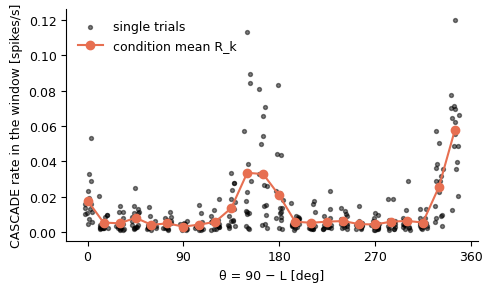

In [4]:
from adamacs.responsiveness.zeta_tools import seed_for
pick = D["cascade25"].query("hotelling_p < 0.001 and fit_r2_cv > 0.7 and fit_chi2_p > 0.05 and fit_at_bound == 0")
row = pick.sort_values("gosi", ascending=False).iloc[len(pick) // 4] if len(pick) else D["cascade25"].sort_values("hotelling_p").iloc[0]
ck = {c: row[c] for c in CELL}
rk = {**ck, "event_selector": "gratings", "trace_source": "cascade25", "readout_idx": 16}
trials = (r.Readout.Cell & rk).fetch1("trial_resp").astype(float)
labels = (r.EventSet.Onset & rk).fetch("condition", order_by="onset_idx")
theta = T.to_angle(labels.astype(float), CONV)
angles = np.unique(theta)
means = np.array([np.nanmean(trials[theta == a]) for a in angles])
print(f"cell {ck['scan_id']} mask {ck['mask']}: {np.isfinite(trials).sum()} trials, {angles.size} directions, "
      f"{int(np.min([np.sum(np.isfinite(trials[theta == a])) for a in angles]))}-{int(np.max([np.sum(np.isfinite(trials[theta == a])) for a in angles]))} per direction")
fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(theta + np.random.default_rng(0).uniform(-4, 4, theta.size), trials, s=8, alpha=.5, color="k", label="single trials")
ax.plot(angles, means, "o-", color="#e76f51", label="condition mean R_k")
ax.set(xlabel="θ = 90 − L [deg]", ylabel="CASCADE rate in the window [spikes/s]", xticks=range(0, 361, 90)); ax.legend()
plt.tight_layout(); plt.show()

**Step 2: vector sums.** Each condition mean is a vector of length R_k at angle θ_k (direction, F₁) or at 2θ_k
(orientation, F₂: opposite directions point the same way). The normalised length of the sum is `gdsi` / `gosi`, its
angle `pref_dir` / 2 × `pref_ori`. With `rectify = 'clip'`, negative means are set to 0 first.

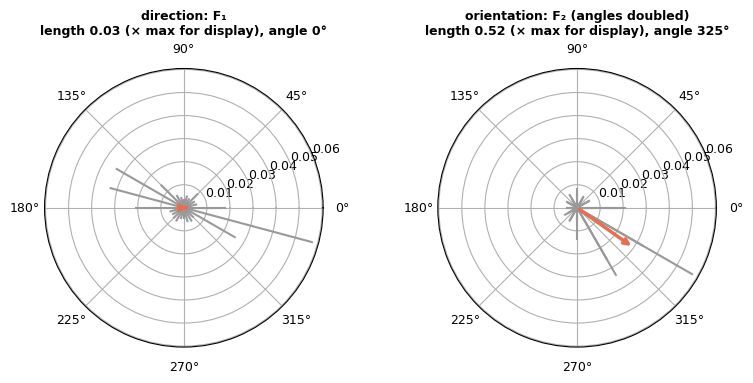

gdsi = 0.029, gosi = 0.521, pref_dir = 0.4°, pref_ori = 162.4°


In [5]:
m = T.rectify(means, TP["rectify"])
g_o, g_d, p_o, p_d = T.vector_measures(angles, m)
th = np.deg2rad(angles)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.8), subplot_kw=dict(projection="polar"))
for ax, n, val, pref, name in ((axs[0], 1, g_d, p_d, "direction: F₁"), (axs[1], 2, g_o, p_o * 2, "orientation: F₂ (angles doubled)")):
    for a, rk_ in zip(th, m):
        ax.plot([0, n * a], [0, rk_], color="0.6", lw=1.5)
    F = np.sum(m * np.exp(1j * n * th)) / np.sum(m)
    ax.annotate("", xy=(np.angle(F), abs(F) * m.max()), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#e76f51", lw=2.5))
    ax.set_title(f"{name}\nlength {val:.2f} (× max for display), angle {pref % 360:.0f}°", fontsize=9)
plt.tight_layout(); plt.show()
print(f"gdsi = {g_d:.3f}, gosi = {g_o:.3f}, pref_dir = {p_d:.1f}°, pref_ori = {p_o:.1f}°")

**Step 3: everything else, and the comparison with the table.** The tests (Hotelling, dot product, Kruskal-Wallis),
the shuffle and bootstrap, the split-half selectivity, the point indices and the fit, all from the same trials.

In [6]:
seed = seed_for(ck["scan_id"], ck["mask"])
res = T.direction_tuning(trials, labels, TP["rectify"], bool(TP["fit"]), int(TP["n_perm"]), int(TP["n_boot"]), seed=seed, angle_convention=CONV)
stored = (r.DirectionTuning.Cell & {**rk, "tuning_idx": 1}).fetch1()
src = {c: c for c in COLS}; src.update(fit_osi="fit_osi_fit", fit_dsi="fit_dsi_fit", fit_oi="fit_oi_fit", fit_di="fit_di_fit")
cmp = []
for c in COLS:
    a = res.get(src[c]); a = T.stored_angle(a, T.ANGLE_PERIODS[c]) if c in T.ANGLE_PERIODS else a
    b = stored[c]
    a = np.nan if a is None else float(a); b = np.nan if b is None else float(b)
    cmp.append(dict(column=c, recomputed=a, stored=b, match=(np.isnan(a) and np.isnan(b)) or abs(a - b) <= 1e-4 * max(1, abs(a))))
cmp = pd.DataFrame(cmp)
display(cmp.round(4))
print(f"{int(cmp.match.sum())} of {len(cmp)} columns match the stored row (float32 storage, tolerance 1e-4 relative)")

,column,recomputed,stored,match
0,gosi,0.5211,0.5211,True
1,gdsi,0.0290,0.0290,True
2,gosi_cv,0.5218,0.5218,True
3,gdsi_cv,0.0265,0.0265,True
4,gosi_perm_p,0.0010,0.0010,True
5,gdsi_perm_p,0.8701,0.8701,True
6,pref_ori,162.3924,162.3920,True
7,pref_dir,0.3735,0.3735,True
8,pref_dir_dot,342.3924,342.3920,True
9,pref_ori_ci,5.4161,5.4161,True


33 of 33 columns match the stored row (float32 storage, tolerance 1e-4 relative)


## 4. The population

* **Selectivity.** `gosi` is the recommended orientation selectivity. It is biased upwards when a cell is noisy;
  `gosi_cv` removes that bias (≤ 0 = no reliable tuning) and is the one to compare across cells and sessions.
* **`gosi` vs `osi`.** The point index `osi` is always larger than `gosi` for the same cell: the two are different
  measures, not two estimates of one, so never mix them across studies.
* **Tested tuning.** `hotelling_p` (orientation) is calibrated: 3–6 % of cells reach p < 0.05 on random stimulus onsets
  (design doc section 2.6).
* **Preferred orientations** mean something only for tuned cells (Hotelling p < 0.05).

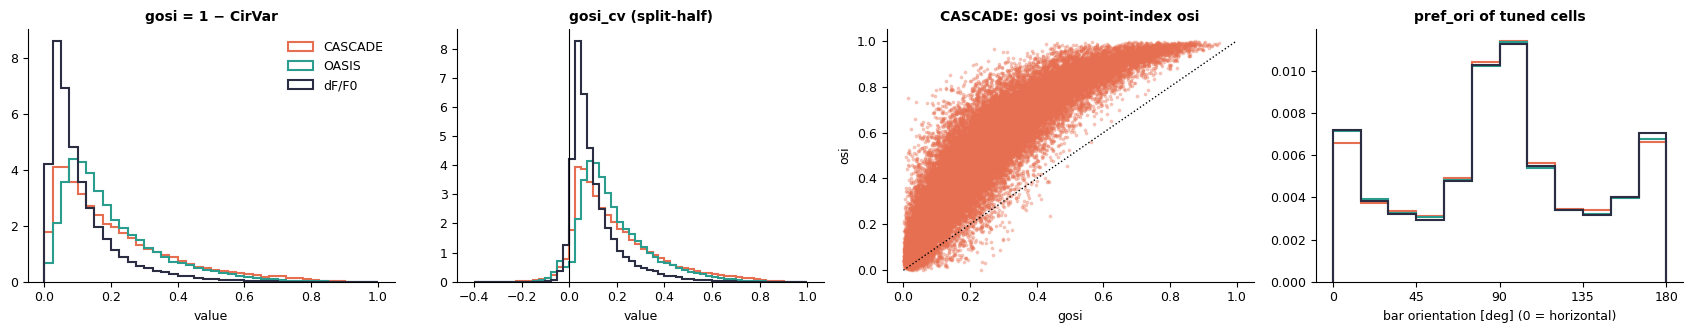

,CASCADE,OASIS,dF/F0
median gosi,0.156,0.158,0.076
median gosi_cv,0.146,0.151,0.072
% Hotelling p < 0.05,80.109,80.410,80.784
% gosi_perm_p < 0.05,83.076,83.438,83.992
% direction tuned (dot p < 0.05),50.417,49.650,48.302


In [7]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for s, d in D.items():
    ax[0].hist(d.gosi.dropna(), bins=np.linspace(0, 1, 41), histtype="step", lw=1.5, color=COL[s], label=NAME[s], density=True)
    ax[1].hist(d.gosi_cv.dropna(), bins=np.linspace(-.4, 1, 57), histtype="step", lw=1.5, color=COL[s], density=True)
    ax[3].hist(d[d.hotelling_p < .05].pref_ori.dropna(), bins=np.arange(0, 181, 15), histtype="step", lw=1.5, color=COL[s], density=True)
c = D["cascade25"]
ax[2].scatter(c.gosi, c.osi, s=3, alpha=.3, color=COL["cascade25"]); ax[2].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set(title="gosi = 1 − CirVar", xlabel="value"); ax[0].legend()
ax[1].set(title="gosi_cv (split-half)", xlabel="value"); ax[1].axvline(0, color="k", lw=.8)
ax[2].set(title="CASCADE: gosi vs point-index osi", xlabel="gosi", ylabel="osi")
ax[3].set(title="pref_ori of tuned cells", xlabel="bar orientation [deg] (0 = horizontal)", xticks=range(0, 181, 45))
plt.tight_layout(); plt.show()
tab = pd.DataFrame({NAME[s]: {"median gosi": d.gosi.median(), "median gosi_cv": d.gosi_cv.median(),
                              "% Hotelling p < 0.05": 100 * np.mean(d.hotelling_p < .05),
                              "% gosi_perm_p < 0.05": 100 * np.mean(d.gosi_perm_p < .05),
                              "% direction tuned (dot p < 0.05)": 100 * np.mean(d.dir_dot_p < .05)} for s, d in D.items()}).round(3)
display(tab)

## 5. Three trace types, one cell

The same ROI has a tuning row for CASCADE, OASIS and dF/F0. For cells that are tuned in two trace types, the
preferred orientations should agree; their circular difference shows how much the choice of trace matters.

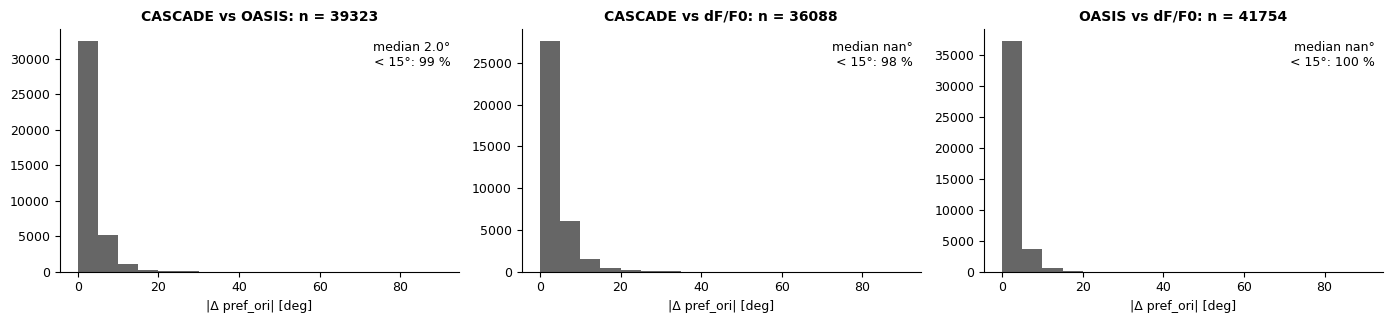

gosi CASCADE vs OASIS (both tuned): Spearman 0.6


In [8]:
def paired(a, b):
    x = D[a][CELL + ["pref_ori", "hotelling_p", "gosi"]].merge(D[b][CELL + ["pref_ori", "hotelling_p", "gosi"]], on=CELL, suffixes=("_a", "_b"))
    x = x[(x.hotelling_p_a < .05) & (x.hotelling_p_b < .05)]
    return x, np.abs(T._angdiff(x.pref_ori_a - x.pref_ori_b, 180))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
for i, (a, b) in enumerate((("cascade25", "oasis"), ("cascade25", "dff0_r2"), ("oasis", "dff0_r2"))):
    x, dif = paired(a, b)
    ax[i].hist(dif, bins=np.arange(0, 91, 5), color="0.4")
    ax[i].set(title=f"{NAME[a]} vs {NAME[b]}: n = {len(x)}", xlabel="|Δ pref_ori| [deg]")
    if len(x):
        ax[i].text(.98, .95, f"median {np.median(dif):.1f}°\n< 15°: {100 * np.mean(dif < 15):.0f} %", transform=ax[i].transAxes, ha="right", va="top")
plt.tight_layout(); plt.show()
x, _ = paired("cascade25", "oasis")
if len(x):
    print("gosi CASCADE vs OASIS (both tuned): Spearman", round(x[["gosi_a", "gosi_b"]].corr(method="spearman").iloc[0, 1], 2))

## 6. The double-Gaussian fit and its goodness of fit

R(θ) = C + Rp·G(θ − θp) + Rn·G(θ − θp − 180), G(x) = exp(−x² / 2σ²) (Mazurek et al. 2014), fitted to the
(unrectified) condition means; Rp is always the larger peak. Five parameters on 12 points describe noise well too:
the in-sample `fit_r2` is 0.41–0.44 (median) on random onsets. The goodness-of-fit columns separate real fits:

* `fit_r2_cv`: fitted on the odd trials' means, R² on the even trials' means (and reverse). ≤ 0 = predicts nothing.
* `fit_chi2_p`: χ² of the fit against the means with the pooled trial SEM; small = the model does not describe
  the curve.
* `fit_at_bound`: width at its limit, offset or amplitude at a bound, Rp at 0, or no convergence.

Report fit values only where `hotelling_p < 0.05 AND fit_r2_cv > 0.5 AND fit_chi2_p > 0.05`.

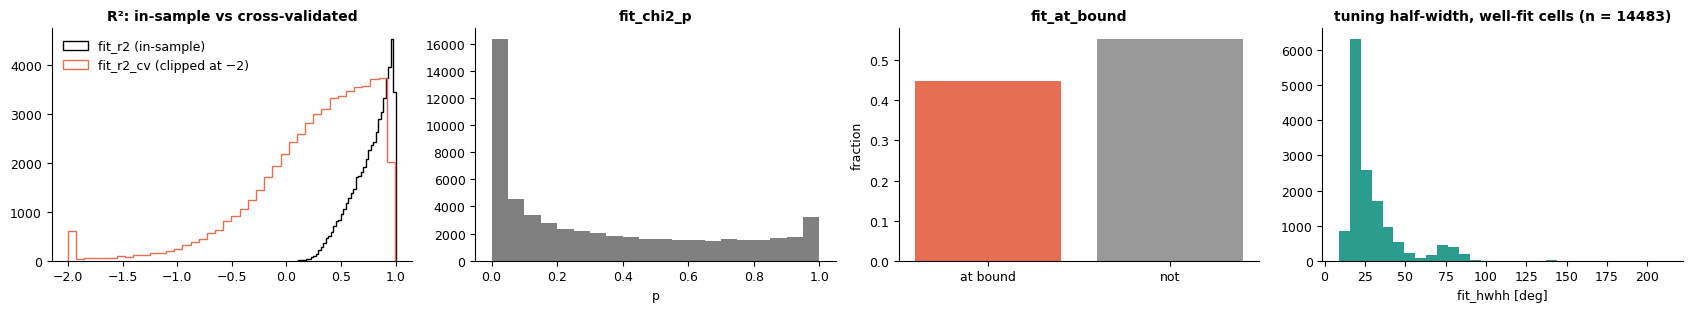

well-fit: 14483 of 56287 responsive + reliable CASCADE cells (26 %); of the orientation-tuned ones: 32 %


In [9]:
c = D["cascade25"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
ax[0].hist(c.fit_r2.dropna(), bins=40, histtype="step", color="k", label="fit_r2 (in-sample)")
ax[0].hist(c.fit_r2_cv.dropna().clip(-2, 1), bins=40, histtype="step", color=COL["cascade25"], label="fit_r2_cv (clipped at −2)")
ax[0].set(title="R²: in-sample vs cross-validated"); ax[0].legend()
ax[1].hist(c.fit_chi2_p.dropna(), bins=20, color="0.5"); ax[1].set(title="fit_chi2_p", xlabel="p")
ax[2].bar(["at bound", "not"], [np.mean(c.fit_at_bound == 1), np.mean(c.fit_at_bound == 0)], color=["#e76f51", "0.6"]); ax[2].set(title="fit_at_bound", ylabel="fraction")
w = c.query("hotelling_p < 0.05 and fit_r2_cv > 0.5 and fit_chi2_p > 0.05")
ax[3].hist(w.fit_hwhh.dropna(), bins=30, color="#2a9d8f"); ax[3].set(title=f"tuning half-width, well-fit cells (n = {len(w)})", xlabel="fit_hwhh [deg]")
plt.tight_layout(); plt.show()
print(f"well-fit: {len(w)} of {len(c)} responsive + reliable CASCADE cells ({100 * len(w) / max(len(c), 1):.0f} %); "
      f"of the orientation-tuned ones: {100 * len(w) / max((c.hotelling_p < .05).sum(), 1):.0f} %")

**Good and rejected fits side by side.** Top row: cells that pass the criterion. Bottom row: cells with a high
in-sample R² (> 0.6) that fail cross-validation, i.e. fits of noise. Black: condition means ± SEM; red: the fitted
curve rebuilt from the five stored parameters.

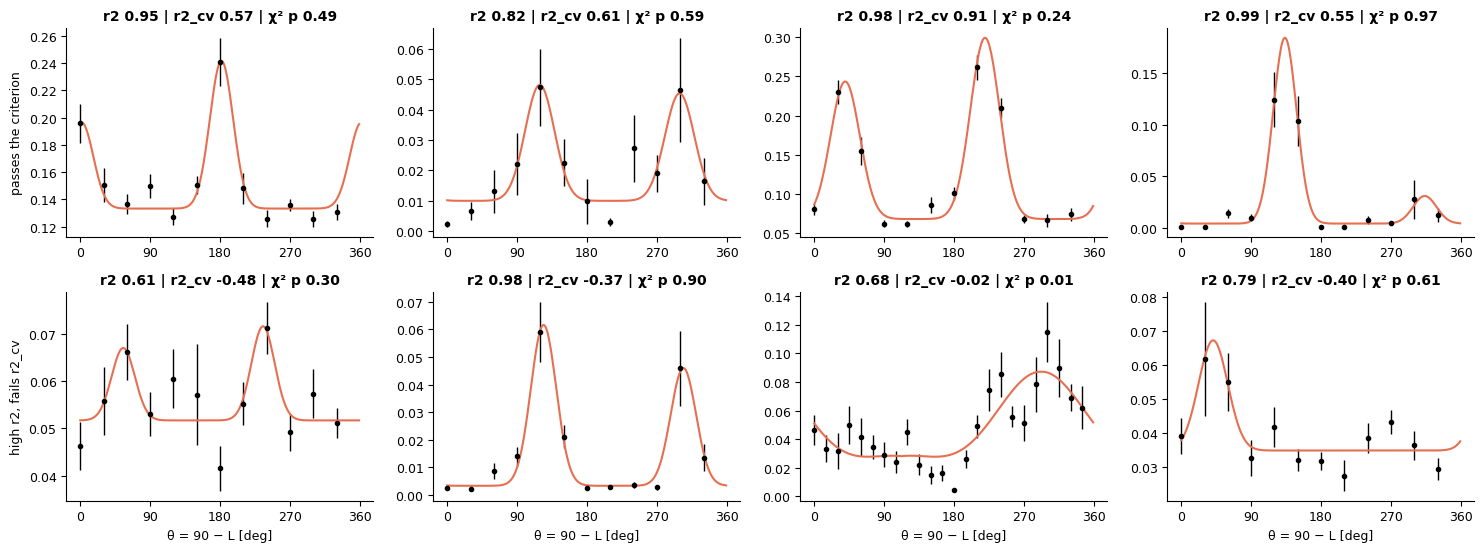

In [10]:
FIT = ["fit_c", "fit_rp", "fit_rn", "fit_pref_dir", "fit_sigma"]
def show(ax, rw):
    k = {**{cc: rw[cc] for cc in CELL}, "event_selector": "gratings", "trace_source": "cascade25", "readout_idx": 16}
    lab, mu, se = (r.Readout.Condition & k).fetch("condition", "resp", "resp_sem")
    th_ = T.to_angle(lab.astype(float), CONV); o = np.argsort(th_)
    ax.errorbar(th_[o], mu[o].astype(float), yerr=se[o].astype(float), fmt="o", ms=3, color="k", lw=1)
    g = np.arange(0, 360, 1.0)
    ax.plot(g, T._double_gauss([float(rw[f]) for f in FIT], g), color="#e76f51")
    ax.set(xticks=range(0, 361, 90), title=f"r2 {rw.fit_r2:.2f} | r2_cv {rw.fit_r2_cv:.2f} | χ² p {rw.fit_chi2_p:.2f}")
good_ = c.query("hotelling_p < 0.05 and fit_r2_cv > 0.5 and fit_chi2_p > 0.05").sample(min(4, len(w)), random_state=1)
bad_ = c.query("fit_r2 > 0.6 and fit_r2_cv < 0").sample(4, random_state=1) if (c.eval("fit_r2 > 0.6 and fit_r2_cv < 0")).sum() >= 4 else c.iloc[:0]
fig, axs = plt.subplots(2, 4, figsize=(15, 5.6), squeeze=False)
for j, (_, rw) in enumerate(good_.iterrows()): show(axs[0][j], rw)
for j, (_, rw) in enumerate(bad_.iterrows()): show(axs[1][j], rw)
axs[0][0].set_ylabel("passes the criterion"); axs[1][0].set_ylabel("high r2, fails r2_cv")
for a in axs[1]: a.set_xlabel("θ = 90 − L [deg]")
plt.tight_layout(); plt.show()

**Fit-based vs measured indices.** `fit_osi` (normalised, on the fitted curve) and `fit_oi` (the VH-lab wiki's
fit-based OSI, (R_p − R_o)/R_p) next to the measured `osi`, for well-fit cells.

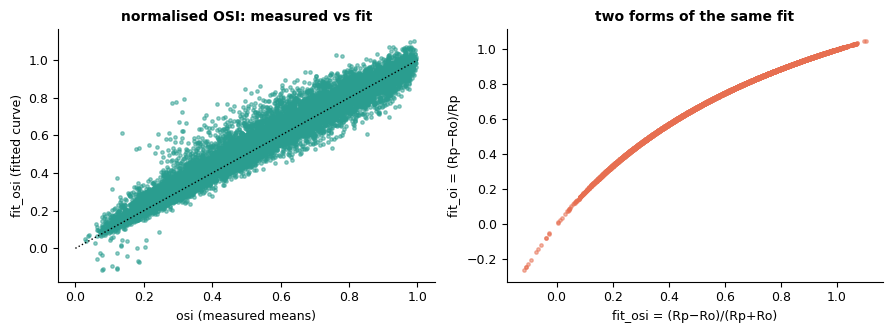

In [11]:
if len(w):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
    ax[0].scatter(w.osi, w.fit_osi, s=6, alpha=.5, color="#2a9d8f"); ax[0].plot([0, 1], [0, 1], "k:", lw=1)
    ax[0].set(xlabel="osi (measured means)", ylabel="fit_osi (fitted curve)", title="normalised OSI: measured vs fit")
    ax[1].scatter(w.fit_osi, w.fit_oi, s=6, alpha=.5, color="#e76f51")
    ax[1].set(xlabel="fit_osi = (Rp−Ro)/(Rp+Ro)", ylabel="fit_oi = (Rp−Ro)/Rp", title="two forms of the same fit")
    plt.tight_layout(); plt.show()

## 7. Direction selectivity

`gdsi` (vector), `dsi` (point index), the direction test `dir_dot_p` (projection of each repeat's direction vector on
the preferred orientation axis, Mazurek et al. 2014) and the preferred direction from that test (`pref_dir_dot`,
= `pref_ori` or `pref_ori` + 180). For direction-tuned cells, `pref_dir` and `pref_dir_dot` should agree.

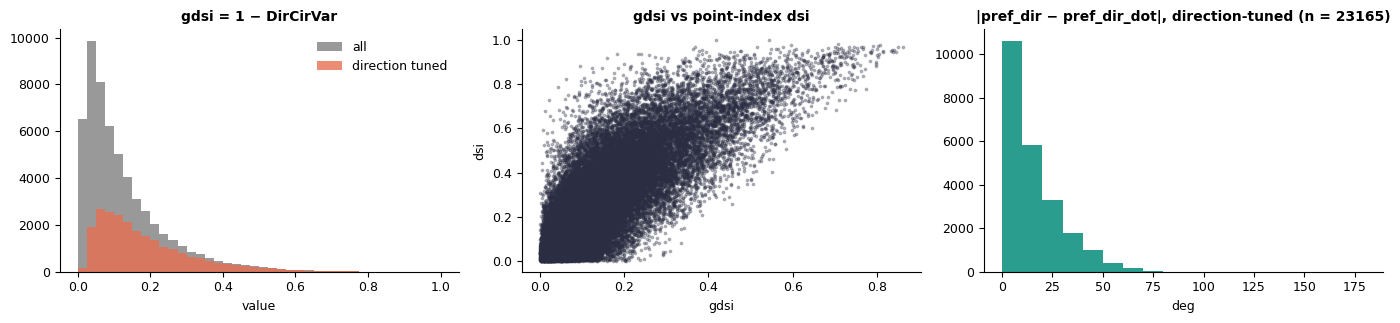

In [12]:
c = D["cascade25"]
dt = c[(c.dir_dot_p < .05) & (c.hotelling_p < .05)]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].hist(c.gdsi.dropna(), bins=np.linspace(0, 1, 41), color="0.6", label="all")
ax[0].hist(dt.gdsi.dropna(), bins=np.linspace(0, 1, 41), color="#e76f51", alpha=.8, label="direction tuned"); ax[0].legend()
ax[0].set(title="gdsi = 1 − DirCirVar", xlabel="value")
ax[1].scatter(c.gdsi, c.dsi, s=3, alpha=.3, color="#2b2d42"); ax[1].set(title="gdsi vs point-index dsi", xlabel="gdsi", ylabel="dsi")
dd = np.abs(T._angdiff(dt.pref_dir - dt.pref_dir_dot, 360))
ax[2].hist(dd, bins=np.arange(0, 181, 10), color="#2a9d8f"); ax[2].set(title=f"|pref_dir − pref_dir_dot|, direction-tuned (n = {len(dt)})", xlabel="deg")
plt.tight_layout(); plt.show()

## 8. Caveats: what to treat with care

* **Read-out 16 is the raw response mean**, without baseline subtraction (the v1-drift-audit's convention). Selectivity
  is relative to the total response including spontaneous activity: the same tuning curve on a higher spontaneous
  level gives a lower `gosi` / `osi`.
* **dF/F0 is for display**, not for calls. In 4 two-plane ROS-1684 scans (`scan9FMJRE5I`, `-SNPT`, `-QWA1`, `-QWA6`)
  7–48 % of ROIs still have F0 ≤ 0 (mostly ROIs in a dark band at the top of the image); `Dff0.Trace.f0_nonpositive`
  flags them. Their dF/F0 and CASCADE values need care.
* **Fallback dark signal (fixed 2026-11-26).** 11 recordings without shutter events had subtracted their own signal
  as "dark"; their dF/F0, CASCADE and responsiveness rows were recomputed with element roselab-0.1.0b3.
* **Second channel.** Two-channel recordings store the masks of the non-functional channel as `fluo_channel 1`;
  `imaging.RoiQC.Rejected` (`second_channel`) excludes them. Always subtract `RoiQC.Rejected`.
* **Few repeats.** Recordings with 2 repeats per direction (e.g. the 2023 WEZ-8872 scans) cannot have a Hotelling p
  (needs 3) and give noisy vector measures.
* **Angles at 180.0 / 360.0.** Rows computed before 2026-11-26 evening can store a preferred angle of exactly 180.0
  (float32 rounding; fixed in PR #45). Read angles modulo their period.

In [13]:
n180 = len(r.DirectionTuning.Cell & SEL & "pref_ori >= 180 OR pref_dir >= 360 OR pref_dir_dot >= 360 OR fit_pref_dir >= 360")
few = r.DirectionTuning & SEL & "n_repeats < 3"
display(Markdown(f"Rows with an angle at its period: **{n180}**. Read-outs with fewer than 3 repeats per direction: "
                 f"**{len(few)}** ({', '.join(sorted(set(few.fetch('scan_id')))[:6])}{' …' if len(few) > 6 else ''})."))

Rows with an angle at its period: **2732**. Read-outs with fewer than 3 repeats per direction: **6** (scan9FIFZ87J, scan9FIFZK9P).

## 9. Query recipes

```python
std = {"event_selector": "gratings", "trace_source": "cascade25", "readout_idx": 16, "tuning_idx": 1}
tuned_ori = r.DirectionTuning.Cell & std & "hotelling_p < 0.05"                  # orientation tuned
tuned_dir = r.DirectionTuning.Cell & std & "dir_dot_p < 0.05"                    # direction tuned
reliable  = r.DirectionTuning.Cell & std & "gosi_cv > 0"                          # noise-robust selectivity
well_fit  = r.DirectionTuning.Cell & std & "hotelling_p < 0.05 AND fit_r2_cv > 0.5 AND fit_chi2_p > 0.05"
clean     = r.DirectionTuning.Cell & std & good_cells.proj() - imaging.RoiQC.Rejected.proj()
curve     = r.Readout.Condition & cell_key                                        # measured tuning curve (labels!)
trials    = (r.Readout.Cell & cell_key).fetch1("trial_resp")                      # with EventSet.Onset.condition
```

Labels in `Readout.Condition.condition` and `EventSet.Onset.condition` are raw stimulus labels L. Convert them with
`adamacs.responsiveness.tuning.to_angle(L, "90_minus_label")` before comparing them with `pref_ori` / `pref_dir`, and
rebuild a fitted curve with `adamacs.responsiveness.tuning._double_gauss([fit_c, fit_rp, fit_rn, fit_pref_dir, fit_sigma], θ)`.